<a href="https://colab.research.google.com/github/Janeth172/EDP1/blob/main/Calculo_SMA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **TAREA**

Realizar un programa en Python que consultando una base de datos. Calcule **SMA**, **WMA** y **EMA** de un menú de acciones


**Instalación de librerías**

Estas librerías servirán posteriormente para descargar, organizar y analizar datos históricos del mercado bursátil.

In [ ]:
# INSTALAR LIBRERIAS
!pip install -q pandas_datareader yfinance3

**Importación de librerías**

`pandas_datareader`: Permite acceder a información financiera y económica de diferentes fuentes de datos

`yfinance`: Obtener información financiera de Yahoo Finance

`pandas`: Manipulación y análisis de datos estructurados

`numPy`: Operaciones matemáticas y cálculos numéricos

`matplotlib.pyplot`: Representaciones gráficas de los datos

In [ ]:
# LIBRERÍAS A UTILIZAR
from pandas_datareader import data
import yfinance as yf
import pandas as pd
import numpy as  np
import matplotlib.pyplot as plt

**Definir fehchas y fuente de información**

Se estableció un intervalo de tiempo específico de un año para la consulta de información financiera en Yahoo Finance

In [ ]:
# Fuente de obtención de información
data_source = 'yahoo'

# Fecha inicio
start_date = '2025-01-01'

# Fecha termino
end_date = '2026-10-24'

start_date_2 = '2025-01-01'
end_date_2 = '2026-10-24'

In [ ]:
# PONER LA ACCIÓN
clave = 'GOOGL'

In [ ]:
# DESCARGAR LAS COTIZACIONES
Cotizaciones = yf.download(
    clave,
    start_date,
    end_date,
    auto_adjust = False
)

[*********************100%***********************]  1 of 1 completed


In [ ]:
# MOSTRAR LAS COTIZACIONES
print(Cotizaciones)

Price        Adj Close       Close        High         Low        Open  \
Ticker           GOOGL       GOOGL       GOOGL       GOOGL       GOOGL   
Date                                                                     
2025-01-02  188.324661  189.429993  192.000000  187.500000  190.649994   
2025-01-03  190.670883  191.789993  193.210007  189.979996  191.369995   
2025-01-06  195.721252  196.869995  198.220001  193.850006  193.979996   
2025-01-07  194.349304  195.490005  201.000000  194.600006  197.110001   
2025-01-08  192.818268  193.949997  196.289993  192.380005  192.570007   
...                ...         ...         ...         ...         ...   
2026-10-19  344.179993  344.179993  346.579987  341.850006  343.670013   
2026-10-20  340.279999  340.279999  344.769989  338.359985  343.649994   
2026-10-21  334.760010  334.760010  337.269989  330.380005  336.980011   
2026-10-22  324.220001  324.220001  331.429993  322.000000  330.459991   
2026-10-23  320.209991  320.209991  32

In [ ]:
# CALCULO SMA

# Extraer el precio de cierre
precios = Cotizaciones['Close']

if isinstance(precios, pd.DataFrame):
  precios = precios.iloc[:, 0]

# Calcular SMA de 5 días
SMA_5 = precios.rolling(window=5).mean()
print(SMA_5)



Date
2025-01-02           NaN
2025-01-03           NaN
2025-01-06           NaN
2025-01-07           NaN
2025-01-08    193.505997
                 ...    
2026-10-19    347.082001
2026-10-20    344.382001
2026-10-21    341.806000
2026-10-22    336.806000
2026-10-23    332.729999
Name: GOOGL, Length: 454, dtype: float64


In [ ]:
# CALCULO DE WMA
pesos = np.array([1,2,3,4,5])

WMA = precios.rolling(window=5).apply(
    lambda x: np.dot(x, pesos) / pesos.sum(),
    raw=True)

print(WMA)

Date
2025-01-02           NaN
2025-01-03           NaN
2025-01-06           NaN
2025-01-07           NaN
2025-01-08    194.355331
                 ...    
2026-10-19    345.331999
2026-10-20    343.064665
2026-10-21    339.857334
2026-10-22    333.995335
2026-10-23    328.463332
Name: GOOGL, Length: 454, dtype: float64


In [ ]:
# CALCULO EMA
n = 5
k = 2 / (n+1)
EMA = pd.Series(np.nan, index=precios.index)

# Inicializar con la primera SMA de 5 días
EMA.iloc[n-1] = SMA_5.iloc[n-1]

for i in range(n, len(precios)):
    EMA.iloc[i] = (
        precios.iloc[i] * k + EMA.iloc[i-1] * (1 - k)
    )

print(EMA)

Date
2025-01-02           NaN
2025-01-03           NaN
2025-01-06           NaN
2025-01-07           NaN
2025-01-08    193.505997
                 ...    
2026-10-19    345.879867
2026-10-20    344.013244
2026-10-21    340.928833
2026-10-22    335.359222
2026-10-23    330.309479
Length: 454, dtype: float64


In [ ]:
# Mostrar los tres resultados
Resultados = pd.DataFrame()

Resultados['Precio'] = precios
Resultados['SMA_5'] = SMA_5
Resultados['WMA'] = WMA
Resultados['EMA'] = EMA

print(Resultados)

                Precio       SMA_5         WMA         EMA
Date                                                      
2025-01-02  189.429993         NaN         NaN         NaN
2025-01-03  191.789993         NaN         NaN         NaN
2025-01-06  196.869995         NaN         NaN         NaN
2025-01-07  195.490005         NaN         NaN         NaN
2025-01-08  193.949997  193.505997  194.355331  193.505997
...                ...         ...         ...         ...
2026-10-19  344.179993  347.082001  345.331999  345.879867
2026-10-20  340.279999  344.382001  343.064665  344.013244
2026-10-21  334.760010  341.806000  339.857334  340.928833
2026-10-22  324.220001  336.806000  333.995335  335.359222
2026-10-23  320.209991  332.729999  328.463332  330.309479

[454 rows x 4 columns]


In [ ]:
# Exportar a Excel

from google.colab import files

Datos_Excel = pd.DataFrame()

Datos_Excel['Fecha'] = precios.index
Datos_Excel['Precio'] = precios.values
Datos_Excel['SMA_5'] = SMA_5.values
Datos_Excel['WMA'] = WMA.values
Datos_Excel['EMA'] = EMA.values

Datos_Excel.to_excel('Cotizaciones.xlsx', index=False)

files.download('Cotizaciones.xlsx')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

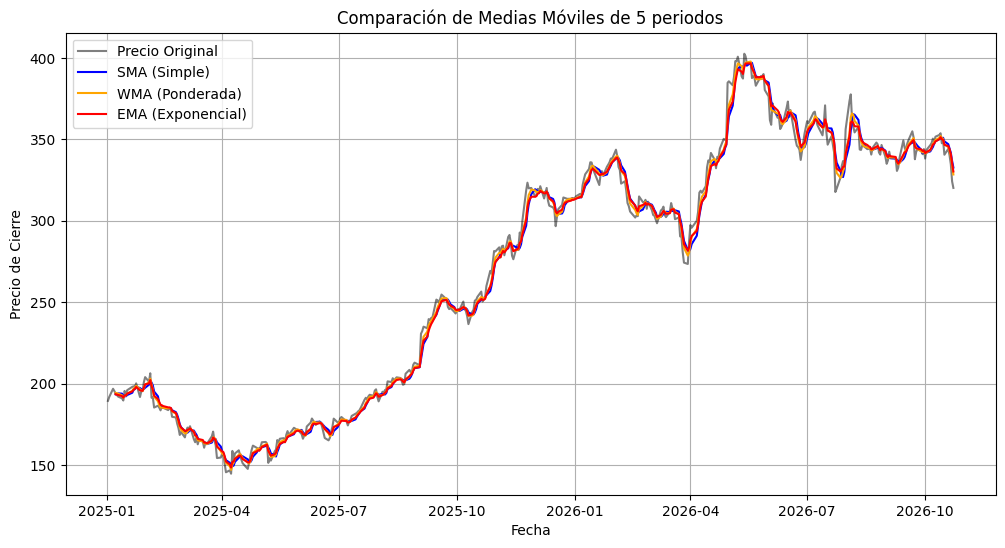

In [ ]:
# 1. Importar la librería de gráficos
import matplotlib.pyplot as plt

# 2. Configurar el tamaño del lienzo (ancho, alto)
plt.figure(figsize=(12, 6))

# 3. Dibujar cada una de las líneas
# alpha=0.5 hace que la línea del precio original sea un poco transparente
plt.plot(precios, label='Precio Original', color='black', alpha=0.5)
plt.plot(SMA_5, label='SMA (Simple)', color='blue')
plt.plot(WMA, label='WMA (Ponderada)', color='orange')
plt.plot(EMA, label='EMA (Exponencial)', color='red')

# 4. Añadir títulos y diseño
plt.title('Comparación de Medias Móviles de 5 periodos')
plt.xlabel('Fecha')
plt.ylabel('Precio de Cierre')

# 5. Mostrar la leyenda (el cuadro que indica qué es cada color)
plt.legend()

# 6. Activar la cuadrícula de fondo para leer mejor los precios
plt.grid(True)

# 7. Desplegar la gráfica final en pantalla
plt.show()